### TEL354 - Minería de Datos
# PAUTA — Taller 1: Análisis de Movilidad y Accesibilidad Urbana en Santiago

> ⚠️ **Documento de uso exclusivo del profesor y ayudantes.** No distribuir a los estudiantes.

**Nombre:** *(Pauta)*

## Preparación del Entorno
### Instalación de Dependencias

In [ ]:
# pip install geopandas scikit-learn matplotlib seaborn umap-learn

### Cargar librerías de trabajo

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from shapely.geometry import Point, Polygon

from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.stats import gaussian_kde
import umap

import warnings
warnings.filterwarnings('ignore')

---
## Parte 1: Carga y Exploración de Datos

### 1.1 Geodatos Regionales

In [2]:
df = gpd.read_file('division_comunal.shp')
df.head()

,NOM_REG,NOM_PROV,NOM_COM,SHAPE_LENG,DIS_ELEC,CIR_SENA,COD_COMUNA,SHAPE_Le_1,SHAPE_Area,geometry
0,Región de La Araucanía,Malleco,Ercilla,170675.595438,48,14,9204,170675.595706,4.979025e+08,"POLYGON ((190393.220 5794527.366, 190474.419 5..."
1,Región de La Araucanía,Malleco,Lonquimay,346907.195437,49,14,9205,346907.195899,3.932854e+09,"POLYGON ((294265.593 5781748.870, 294327.827 5..."
2,Región de La Araucanía,Malleco,Los Sauces,169844.122286,48,14,9206,169844.122239,8.519730e+08,"POLYGON ((155495.103 5804765.810, 155518.319 5..."
3,Región de La Araucanía,Malleco,Lumaco,227705.219204,48,14,9207,227705.218806,1.112643e+09,"POLYGON ((159561.530 5778741.661, 159745.162 5..."
4,Región de La Araucanía,Malleco,Purén,137030.480474,48,14,9208,137030.480353,4.654760e+08,"POLYGON ((145272.593 5804247.707, 145347.984 5..."


### 1.2 Geodatos de Santiago

In [3]:
df_stgo = df[df['NOM_PROV'] == 'Santiago'].to_crs("EPSG:4326")
df_stgo.head()

,NOM_REG,NOM_PROV,NOM_COM,SHAPE_LENG,DIS_ELEC,CIR_SENA,COD_COMUNA,SHAPE_Le_1,SHAPE_Area,geometry
177,Región Metropolitana de Santiago,Santiago,Independencia,11488.695747,19,7,1310,11718.687086,7.514746e+06,"POLYGON ((-70.65730 -33.40479, -70.65729 -33.4..."
178,Región Metropolitana de Santiago,Santiago,La Florida,49696.426793,26,8,1311,49621.402175,7.103733e+07,"POLYGON ((-70.43946 -33.49206, -70.43825 -33.4..."
179,Región Metropolitana de Santiago,Santiago,Lo Barnechea,149539.074262,23,8,1311,149865.511039,1.024735e+09,"POLYGON ((-70.47724 -33.36950, -70.47593 -33.3..."
180,Región Metropolitana de Santiago,Santiago,Lo Espejo,11405.976039,28,8,1311,11389.045242,8.181655e+06,"POLYGON ((-70.69411 -33.50243, -70.69268 -33.5..."
181,Región Metropolitana de Santiago,Santiago,Lo Prado,10795.433316,18,7,1311,10691.672491,6.535088e+06,"POLYGON ((-70.70559 -33.45716, -70.70621 -33.4..."


### 1.3 Visualización del Mapa Base de Santiago

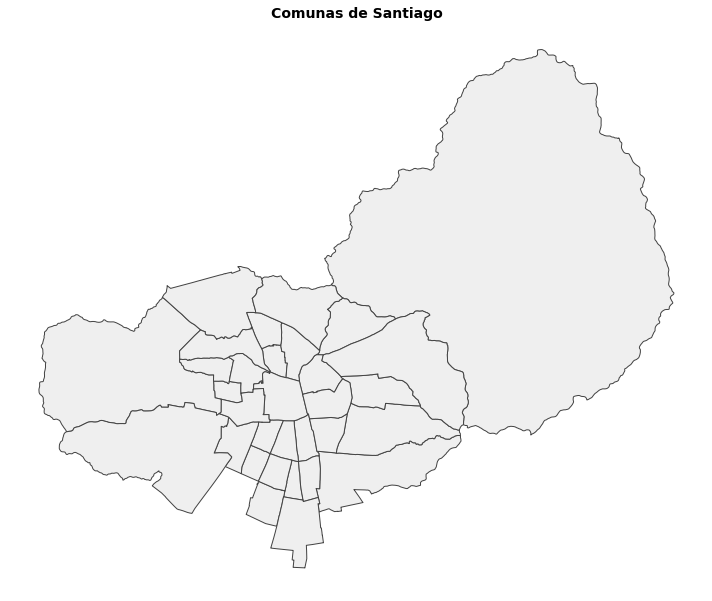

In [4]:
fig, ax = plt.subplots(figsize=(10, 10))
df_stgo.plot(ax=ax, color='#EFEFEF', edgecolor='#444444')
ax.set_title('Comunas de Santiago', fontsize=14, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

### 1.4 Datos de Movilidad y Accesibilidad Urbana

In [5]:
df_mov = pd.read_csv('movilidad.csv')
print(f"Registros: {len(df_mov)}")
print(f"Columnas ({len(df_mov.columns)}): {list(df_mov.columns)}")
df_mov.head()

Registros: 911
Columnas (11): ['comuna', 'longitud', 'latitud', 'dist_metro', 'frec_bus', 'tiempo_viaje', 'indice_acceso', 'tasa_transbordo', 'prop_auto', 'prop_transporte_pub', 'nse']


,comuna,longitud,latitud,dist_metro,frec_bus,tiempo_viaje,indice_acceso,tasa_transbordo,prop_auto,prop_transporte_pub,nse
0,Las Condes,-70.571354,-33.407015,1.095,23.95,15.7,82.58,0.2560,0.6130,0.3870,6.48
1,Las Condes,-70.560638,-33.410403,0.800,21.62,12.2,83.57,0.3110,0.6476,0.3524,6.27
2,Las Condes,-70.560963,-33.413616,1.370,20.83,14.4,84.90,0.3157,0.7119,0.2881,6.88
3,Las Condes,-70.563598,-33.422189,1.375,22.37,22.0,79.84,0.2739,0.6449,0.3551,5.73
4,Las Condes,-70.583769,-33.417437,1.723,19.77,10.0,75.77,0.3683,0.5965,0.4035,5.92


In [6]:
df_mov.describe().round(2)

,longitud,latitud,dist_metro,frec_bus,tiempo_viaje,indice_acceso,tasa_transbordo,prop_auto,prop_transporte_pub,nse
count,911.00,911.00,911.00,911.00,911.00,911.00,911.00,911.00,911.00,911.00
mean,-70.65,-33.47,2.46,16.41,28.08,65.80,0.47,0.44,0.56,3.42
std,0.07,0.07,1.34,3.58,10.32,11.45,0.10,0.12,0.12,1.39
min,-70.80,-33.62,0.30,3.95,10.00,33.50,0.19,0.12,0.13,1.00
25%,-70.70,-33.52,1.35,13.96,20.15,57.92,0.41,0.36,0.49,2.48
50%,-70.65,-33.47,2.28,16.52,27.60,66.21,0.48,0.43,0.57,3.12
75%,-70.60,-33.43,3.30,18.93,35.40,74.22,0.54,0.51,0.64,3.90
max,-70.49,-33.33,6.59,25.94,64.30,95.33,0.80,0.87,0.88,7.00


### 1.5 Distribución del Índice de Accesibilidad

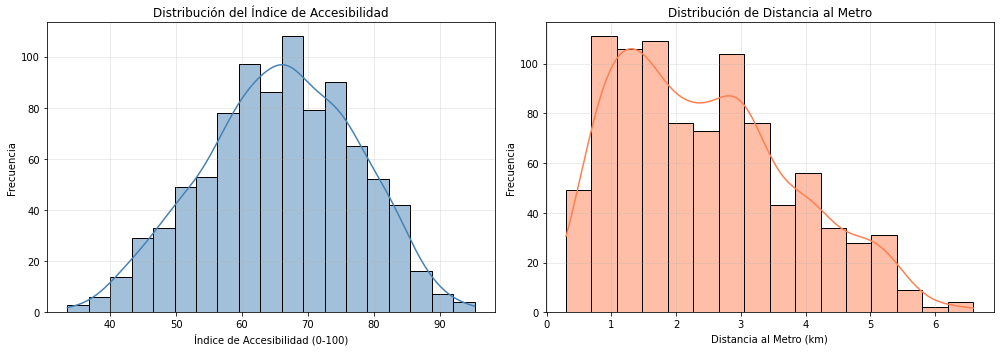

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df_mov['indice_acceso'], kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribución del Índice de Accesibilidad')
axes[0].set_xlabel('Índice de Accesibilidad (0-100)')
axes[0].set_ylabel('Frecuencia')
axes[0].grid(True, alpha=0.3)

sns.histplot(df_mov['dist_metro'], kde=True, ax=axes[1], color='coral')
axes[1].set_title('Distribución de Distancia al Metro')
axes[1].set_xlabel('Distancia al Metro (km)')
axes[1].set_ylabel('Frecuencia')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.6 Visualización Geoespacial del Índice de Accesibilidad

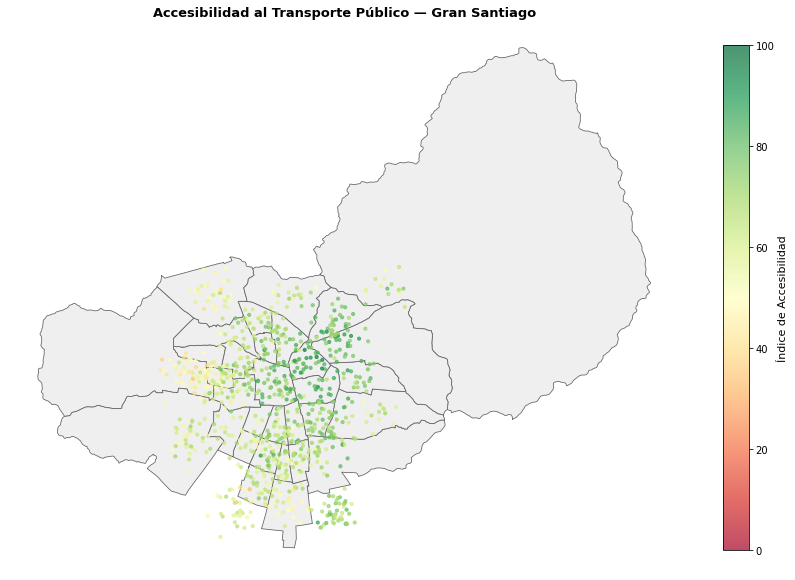

In [8]:
fig, ax = plt.subplots(figsize=(12, 12))
df_stgo.plot(ax=ax, color='#EFEFEF', edgecolor='#666666', linewidth=0.8)
sc = ax.scatter(df_mov['longitud'], df_mov['latitud'],
                c=df_mov['indice_acceso'], cmap='RdYlGn',
                s=10, alpha=0.7, vmin=0, vmax=100)
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label('Índice de Accesibilidad', fontsize=11)
ax.set_title('Accesibilidad al Transporte Público — Gran Santiago',
             fontsize=13, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

---
## Parte 2: Preprocesamiento y Transformación de Datos

### 2.1 Preprocesamiento de Datos

In [9]:
features = ['dist_metro', 'frec_bus', 'tiempo_viaje', 'indice_acceso',
            'tasa_transbordo', 'prop_auto', 'prop_transporte_pub', 'nse']

# Agregación por comuna
comuna_grouped = df_mov.groupby('comuna')[['longitud', 'latitud'] + features].mean().reset_index()

# Estandarización
scaler = StandardScaler()
comuna_scaled = comuna_grouped.copy()
comuna_scaled[features] = scaler.fit_transform(comuna_grouped[features])

# Normalización de nombres para fusión posterior
comuna_grouped['comuna'] = comuna_grouped['comuna'].str.upper()
df_stgo_norm = df_stgo.copy()
df_stgo_norm['NOM_COM'] = df_stgo_norm['NOM_COM'].str.upper()

print(f"Comunas agrupadas: {len(comuna_grouped)}")
comuna_grouped.head()

Comunas agrupadas: 33


,comuna,longitud,latitud,dist_metro,frec_bus,tiempo_viaje,indice_acceso,tasa_transbordo,prop_auto,prop_transporte_pub,nse
0,CERRILLOS,-70.713980,-33.502850,3.050842,14.581579,31.889474,59.687895,0.538916,0.405316,0.594684,2.662105
1,CERRO NAVIA,-70.737232,-33.448965,4.530057,11.414000,38.754286,50.210571,0.591466,0.425909,0.574091,2.220857
2,CONCHALÍ,-70.674687,-33.391468,1.947694,16.490556,28.005556,66.313056,0.478800,0.402900,0.597100,2.963889
3,EL BOSQUE,-70.671664,-33.561257,2.710771,15.176286,31.328571,60.441714,0.525720,0.354620,0.645380,2.268571
4,ESTACIÓN CENTRAL,-70.676898,-33.450190,0.930870,18.702174,21.021739,73.947826,0.438117,0.391074,0.608926,3.468261


### 2.2 Análisis de Correlación de Variables

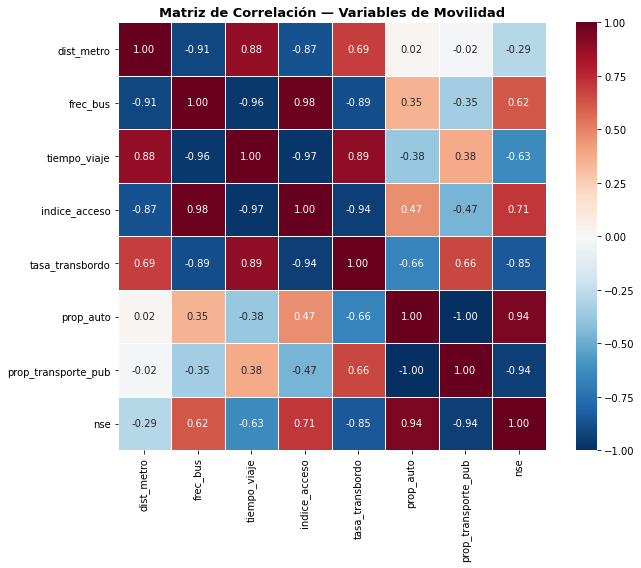

In [10]:
corr = comuna_grouped[features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, square=True, linewidths=0.5)
ax.set_title('Matriz de Correlación — Variables de Movilidad', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---
## Parte 3: Análisis de Clustering

### 3.1 Determinación del Número Óptimo de Clusters

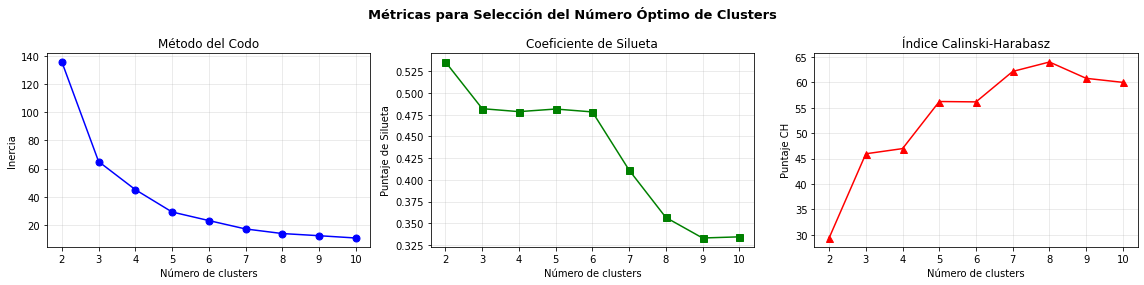


K | Inercia   | Silueta | Calinski-Harabasz
 2 |    135.6 | 0.5357  | 29.3
 3 |     65.0 | 0.4819  | 45.9
 4 |     45.1 | 0.4785  | 47.0
 5 |     29.2 | 0.4815  | 56.2
 6 |     23.2 | 0.4782  | 56.2
 7 |     17.2 | 0.4111  | 62.2
 8 |     14.0 | 0.3566  | 64.0
 9 |     12.4 | 0.3330  | 60.8
10 |     10.8 | 0.3343  | 60.0


In [11]:
X = comuna_scaled[features].values

def evaluar_clusters(X, max_k=10):
    ks = range(2, max_k + 1)
    inercias, silhouettes, ch_scores = [], [], []
    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = km.fit_predict(X)
        inercias.append(km.inertia_)
        silhouettes.append(silhouette_score(X, labels))
        ch_scores.append(calinski_harabasz_score(X, labels))

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].plot(list(ks), inercias, 'bo-', markersize=7)
    axes[0].set_title('Método del Codo'); axes[0].set_xlabel('Número de clusters')
    axes[0].set_ylabel('Inercia'); axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(list(ks), silhouettes, 'gs-', markersize=7)
    axes[1].set_title('Coeficiente de Silueta'); axes[1].set_xlabel('Número de clusters')
    axes[1].set_ylabel('Puntaje de Silueta'); axes[1].grid(True, alpha=0.3)
    
    axes[2].plot(list(ks), ch_scores, 'r^-', markersize=7)
    axes[2].set_title('Índice Calinski-Harabasz'); axes[2].set_xlabel('Número de clusters')
    axes[2].set_ylabel('Puntaje CH'); axes[2].grid(True, alpha=0.3)
    
    plt.suptitle('Métricas para Selección del Número Óptimo de Clusters',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return list(ks), inercias, silhouettes, ch_scores

ks, inercias, silhouettes, ch = evaluar_clusters(X, max_k=10)

print("\nK | Inercia   | Silueta | Calinski-Harabasz")
for i, k in enumerate(ks):
    print(f"{k:2d} | {inercias[i]:8.1f} | {silhouettes[i]:.4f}  | {ch[i]:.1f}")

**📝 Criterio de selección — Pauta:**

Se elige **K = 4** por las siguientes razones:

- **Método del Codo:** La inercia muestra un quiebre visible entre k=3 y k=4; a partir de k=4 la reducción es marginal.
- **Silueta:** El puntaje es estable alrededor de 0.47–0.48 para k=4 y k=5, siendo k=4 el más parsimonioso.
- **Calinski-Harabasz:** Aumenta hasta k=5, pero k=4 es aceptable dado el contexto interpretativo (4 perfiles de movilidad tienen sentido geográfico en Santiago: centro, oriente alto, sur/poniente bajo, periferia extrema).
- **Interpretabilidad:** Con k=4 emergen grupos coherentes con la estructura urbana conocida de Santiago.

**Nota docente:** Aceptar k=3, 4 o 5 si el estudiante justifica con las métricas y la interpretación.

### 3.2 Aplicación de Algoritmos de Clustering

In [12]:
K_OPT = 4  # Número óptimo determinado en 3.1

# ── K-Means ──────────────────────────────────────────────────────────────────
km = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
comuna_scaled['kmeans_cluster'] = km.fit_predict(X)
comuna_grouped['kmeans_cluster'] = comuna_scaled['kmeans_cluster'].values
print(f"K-Means — Silueta: {silhouette_score(X, comuna_scaled['kmeans_cluster']):.4f}")

K-Means — Silueta: 0.4785


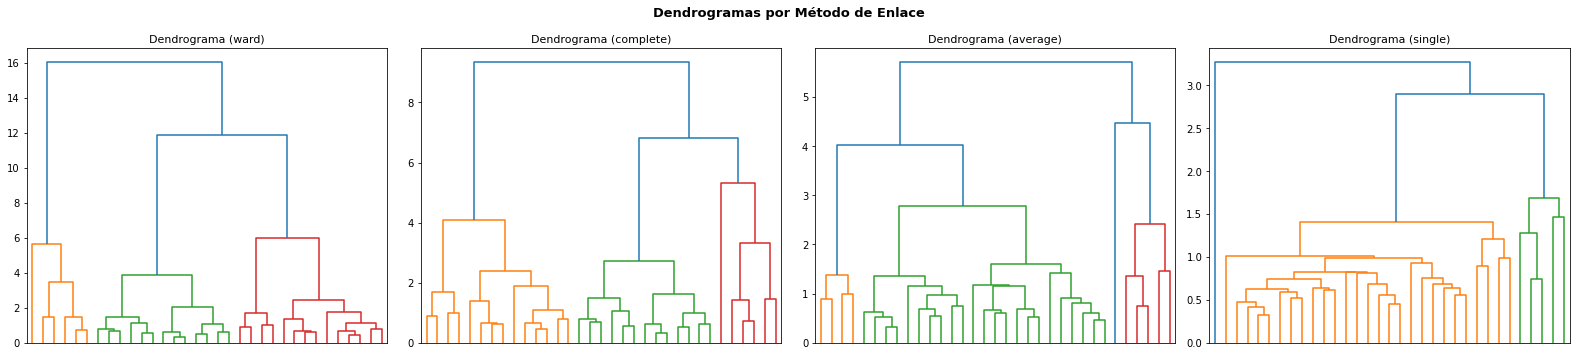

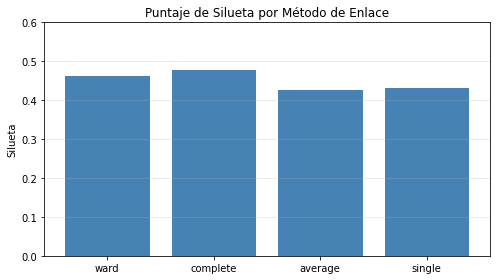

Siluetas por linkage: {'ward': 0.4639741832686978, 'complete': 0.479876701545291, 'average': 0.42941131554216494, 'single': 0.43442060699724006}
Mejor método de enlace: complete (silueta=0.4799)


In [13]:
# ── Clustering Jerárquico ─────────────────────────────────────────────────────
linkage_methods = ['ward', 'complete', 'average', 'single']
sil_linkage = {}

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for i, method in enumerate(linkage_methods):
    Z = linkage(X, method=method)
    dendrogram(Z, ax=axes[i], no_labels=True,
               color_threshold=0.7 * max(Z[:, 2]))
    axes[i].set_title(f'Dendrograma ({method})', fontsize=11)
    agg_tmp = AgglomerativeClustering(n_clusters=K_OPT, linkage=method)
    sil_linkage[method] = silhouette_score(X, agg_tmp.fit_predict(X))

plt.suptitle('Dendrogramas por Método de Enlace', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Comparación de siluetas
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(list(sil_linkage.keys()), list(sil_linkage.values()), color='steelblue', edgecolor='white')
ax.set_title('Puntaje de Silueta por Método de Enlace')
ax.set_ylabel('Silueta'); ax.set_ylim(0, 0.6); ax.grid(axis='y', alpha=0.3)
plt.tight_layout(); plt.show()

best_linkage = max(sil_linkage, key=sil_linkage.get)
print(f"Siluetas por linkage: {sil_linkage}")
print(f"Mejor método de enlace: {best_linkage} (silueta={sil_linkage[best_linkage]:.4f})")

agg_best = AgglomerativeClustering(n_clusters=K_OPT, linkage=best_linkage)
comuna_scaled['agg_cluster'] = agg_best.fit_predict(X)
comuna_grouped['agg_cluster'] = comuna_scaled['agg_cluster'].values

In [14]:
# ── DBSCAN ───────────────────────────────────────────────────────────────────
# Se escoge eps=1.2 y min_samples=2 tras experimentación:
#   - eps más pequeño (0.5-0.8) genera demasiados puntos de ruido
#   - eps=1.2 produce 4 clusters interpretables con pocos outliers
#   - min_samples=2 es razonable dado el pequeño tamaño del dataset (33 comunas)
dbscan = DBSCAN(eps=1.2, min_samples=2)
comuna_scaled['dbscan_cluster'] = dbscan.fit_predict(X)
comuna_grouped['dbscan_cluster'] = comuna_scaled['dbscan_cluster'].values

n_clusters_db = len(set(comuna_scaled['dbscan_cluster']) - {-1})
n_noise       = (comuna_scaled['dbscan_cluster'] == -1).sum()
print(f"DBSCAN — Clusters: {n_clusters_db} | Ruido (outliers): {n_noise}")
mask = comuna_scaled['dbscan_cluster'] != -1
print(f"DBSCAN — Silueta (sin ruido): {silhouette_score(X[mask], comuna_scaled['dbscan_cluster'].values[mask]):.4f}")

DBSCAN — Clusters: 4 | Ruido (outliers): 4
DBSCAN — Silueta (sin ruido): 0.3290


In [15]:
# ── GMM ──────────────────────────────────────────────────────────────────────
gmm = GaussianMixture(n_components=K_OPT, random_state=42)
comuna_scaled['gmm_cluster'] = gmm.fit_predict(X)
comuna_grouped['gmm_cluster'] = comuna_scaled['gmm_cluster'].values
print(f"GMM — Silueta: {silhouette_score(X, comuna_scaled['gmm_cluster']):.4f}")

GMM — Silueta: 0.4637


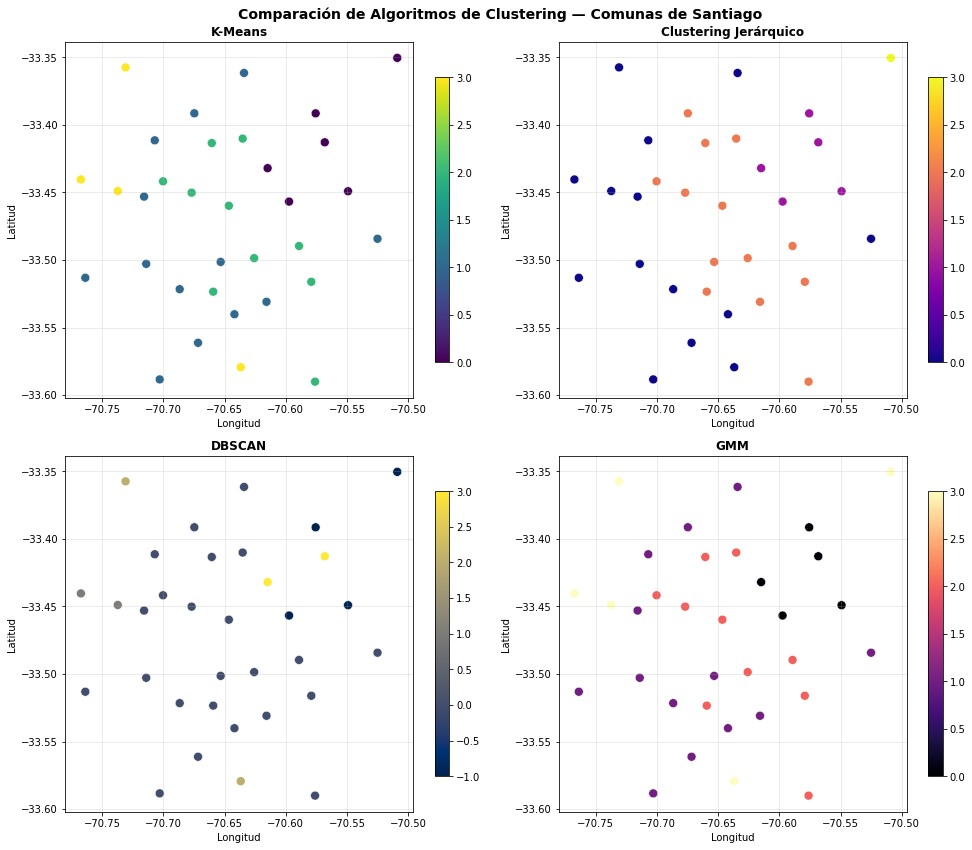

In [16]:
# ── Comparación visual en espacio de coordenadas ──────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
algs = [
    ('kmeans_cluster', 'K-Means',               'viridis'),
    ('agg_cluster',    'Clustering Jerárquico',  'plasma'),
    ('dbscan_cluster', 'DBSCAN',                 'cividis'),
    ('gmm_cluster',    'GMM',                    'magma'),
]
for ax, (col, titulo, cmap) in zip(axes.flat, algs):
    sc = ax.scatter(comuna_grouped['longitud'], comuna_grouped['latitud'],
                    c=comuna_scaled[col], cmap=cmap, s=80, edgecolors='white', linewidths=0.5)
    plt.colorbar(sc, ax=ax, shrink=0.8)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')
    ax.grid(True, alpha=0.3)

plt.suptitle('Comparación de Algoritmos de Clustering — Comunas de Santiago',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 3.3 Fusión con Datos Geoespaciales y Visualización en Mapa

In [17]:
# Fusión
comuna_geo = comuna_grouped.copy()
df_stgo_merged = df_stgo_norm.merge(
    comuna_geo, left_on='NOM_COM', right_on='comuna', how='left'
)
print(f"Filas fusionadas: {len(df_stgo_merged)}")
print(f"NaN en kmeans_cluster: {df_stgo_merged['kmeans_cluster'].isna().sum()}")

Filas fusionadas: 32
NaN en kmeans_cluster: 1


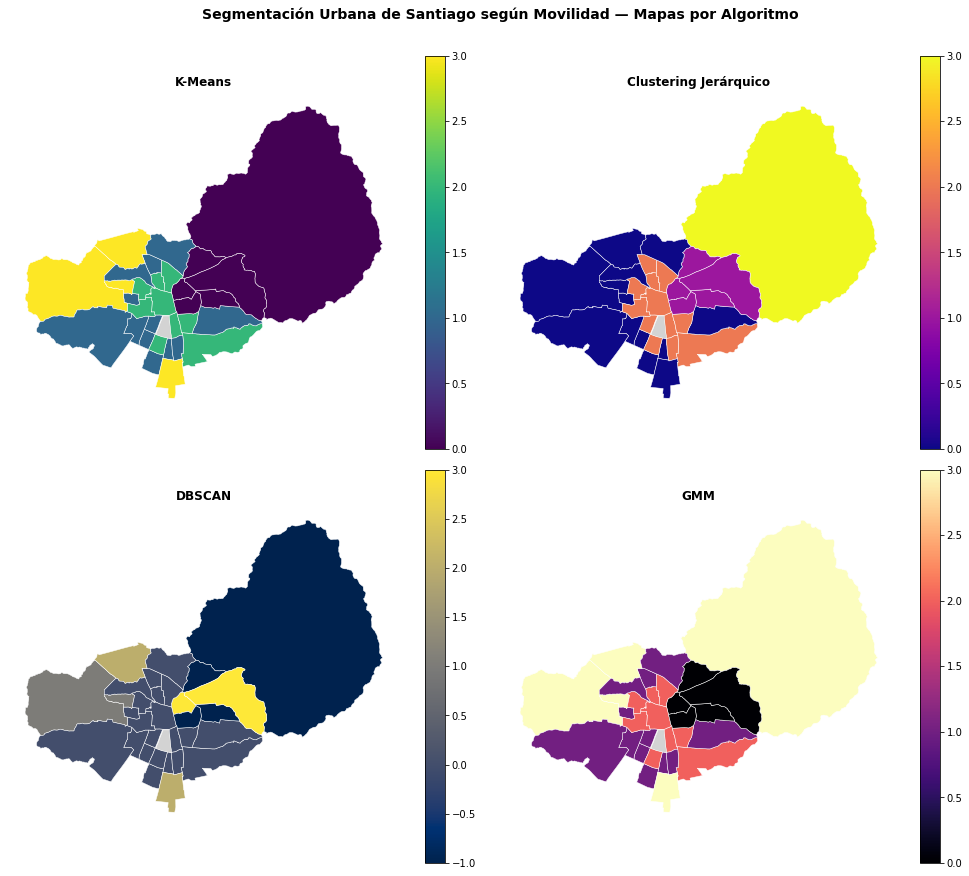

In [18]:
# Mapas
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
algs_map = [
    ('kmeans_cluster', 'K-Means',              'viridis'),
    ('agg_cluster',    'Clustering Jerárquico', 'plasma'),
    ('dbscan_cluster', 'DBSCAN',                'cividis'),
    ('gmm_cluster',    'GMM',                   'magma'),
]
for ax, (col, titulo, cmap) in zip(axes.flat, algs_map):
    df_stgo_merged.plot(column=col, ax=ax, cmap=cmap, legend=True,
                        missing_kwds={'color': 'lightgrey', 'label': 'Sin datos'},
                        edgecolor='white', linewidth=0.5)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.axis('off')

plt.suptitle('Segmentación Urbana de Santiago según Movilidad — Mapas por Algoritmo',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

---
## Parte 4: Perfiles de Movilidad por Cluster

### 4.1 Caracterización de los Clusters

In [19]:
# Estadísticas por cluster
cluster_stats = comuna_grouped.groupby('kmeans_cluster').agg(
    indice_acceso_mean  = ('indice_acceso',       'mean'),
    indice_acceso_std   = ('indice_acceso',        'std'),
    dist_metro_mean     = ('dist_metro',           'mean'),
    tiempo_viaje_mean   = ('tiempo_viaje',         'mean'),
    prop_tp_mean        = ('prop_transporte_pub',  'mean'),
    nse_mean            = ('nse',                  'mean'),
    n_comunas           = ('indice_acceso',       'count'),
).round(2)
print("=== Perfiles por Cluster (K-Means) ===")
cluster_stats

=== Perfiles por Cluster (K-Means) ===


,indice_acceso_mean,indice_acceso_std,dist_metro_mean,tiempo_viaje_mean,prop_tp_mean,nse_mean,n_comunas
kmeans_cluster,,,,,,,
0,76.87,7.46,2.10,21.63,0.39,5.90,6
1,61.45,2.53,2.80,30.30,0.60,2.76,13
2,71.98,2.16,1.31,23.76,0.59,3.33,10
3,50.59,2.31,4.50,38.58,0.57,2.41,4


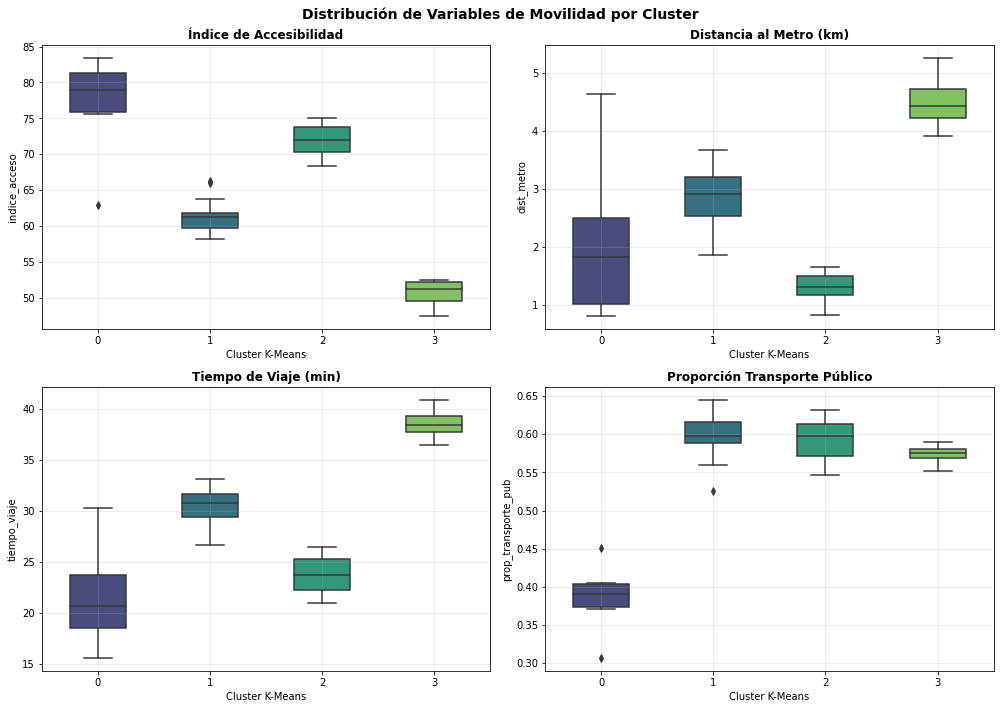

In [20]:
# Boxplots
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (var, titulo) in zip(axes.flat, [
    ('indice_acceso',       'Índice de Accesibilidad'),
    ('dist_metro',          'Distancia al Metro (km)'),
    ('tiempo_viaje',        'Tiempo de Viaje (min)'),
    ('prop_transporte_pub', 'Proporción Transporte Público'),
]):
    sns.boxplot(data=comuna_grouped, x='kmeans_cluster', y=var, ax=ax,
                palette='viridis', width=0.5)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('Cluster K-Means')
    ax.grid(True, alpha=0.3)

plt.suptitle('Distribución de Variables de Movilidad por Cluster', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

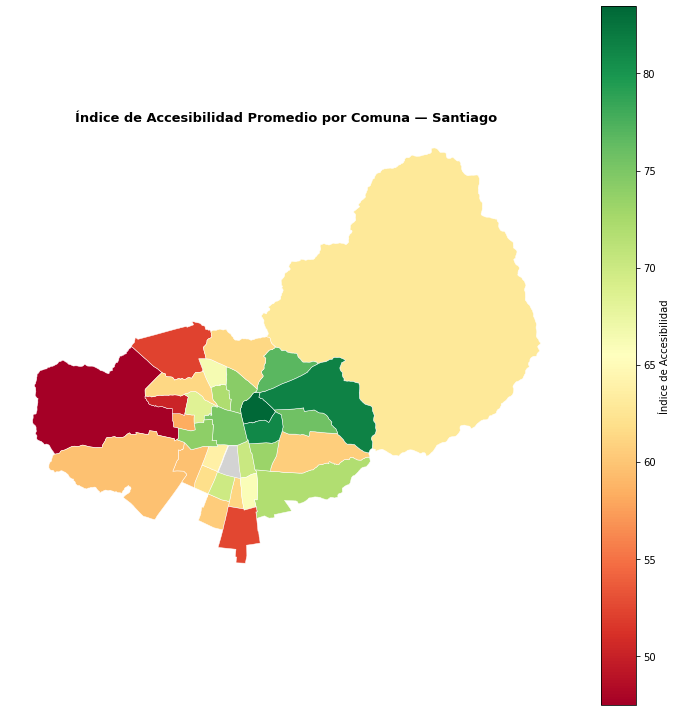

In [21]:
# Mapa coroplético de accesibilidad
fig, ax = plt.subplots(figsize=(10, 10))
df_stgo_merged.plot(column='indice_acceso', ax=ax, cmap='RdYlGn',
                    legend=True,
                    legend_kwds={'label': 'Índice de Accesibilidad', 'orientation': 'vertical'},
                    missing_kwds={'color': 'lightgrey'},
                    edgecolor='white', linewidth=0.5)
ax.set_title('Índice de Accesibilidad Promedio por Comuna — Santiago',
             fontsize=13, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

**📝 Interpretación de perfiles (Pauta):**

| Cluster | Nombre sugerido | Características |
|---|---|---|
| **0** | Alta accesibilidad / alto NSE | Índice acceso >75, NSE ~5.9, dist. metro ~2.1 km, alto uso auto. Comunas del oriente (Providencia, Las Condes, Ñuñoa). |
| **1** | Acceso moderado / NSE medio-bajo | Índice ~61, dist. metro ~2.8 km, alta proporción TP (~60%). Comunas del sur y norte (La Granja, Conchalí, Lo Prado, Maipú). |
| **2** | Buena conectividad central / NSE medio | Índice ~72, dist. metro ~1.3 km, NSE ~3.3. Comunas bien conectadas al metro (Santiago Centro, Estación Central, La Florida). |
| **3** | Periferia con déficit extremo | Índice acceso ~50, dist. metro ~4.5 km, mayor tiempo de viaje (~39 min). Comunas más periféricas: Pudahuel, Quilicura, Cerro Navia. |

**Nota docente:** Aceptar otras denominaciones si están respaldadas en los datos. El punto clave es que el estudiante identifique la gradiente centro-periferia y la correlación NSE-accesibilidad.

---
## Parte 5: Reducción de Dimensionalidad

### 5.1 Análisis de Componentes Principales (PCA)

In [22]:
pca = PCA(n_components=2)
comuna_pca = pca.fit_transform(X)

pca_df = pd.DataFrame({
    'comuna':          comuna_grouped['comuna'],
    'PC1':             comuna_pca[:, 0],
    'PC2':             comuna_pca[:, 1],
    'kmeans_cluster':  comuna_scaled['kmeans_cluster'],
    'agg_cluster':     comuna_scaled['agg_cluster'],
    'dbscan_cluster':  comuna_scaled['dbscan_cluster'],
    'gmm_cluster':     comuna_scaled['gmm_cluster'],
    'indice_acceso':   comuna_grouped['indice_acceso'],
})

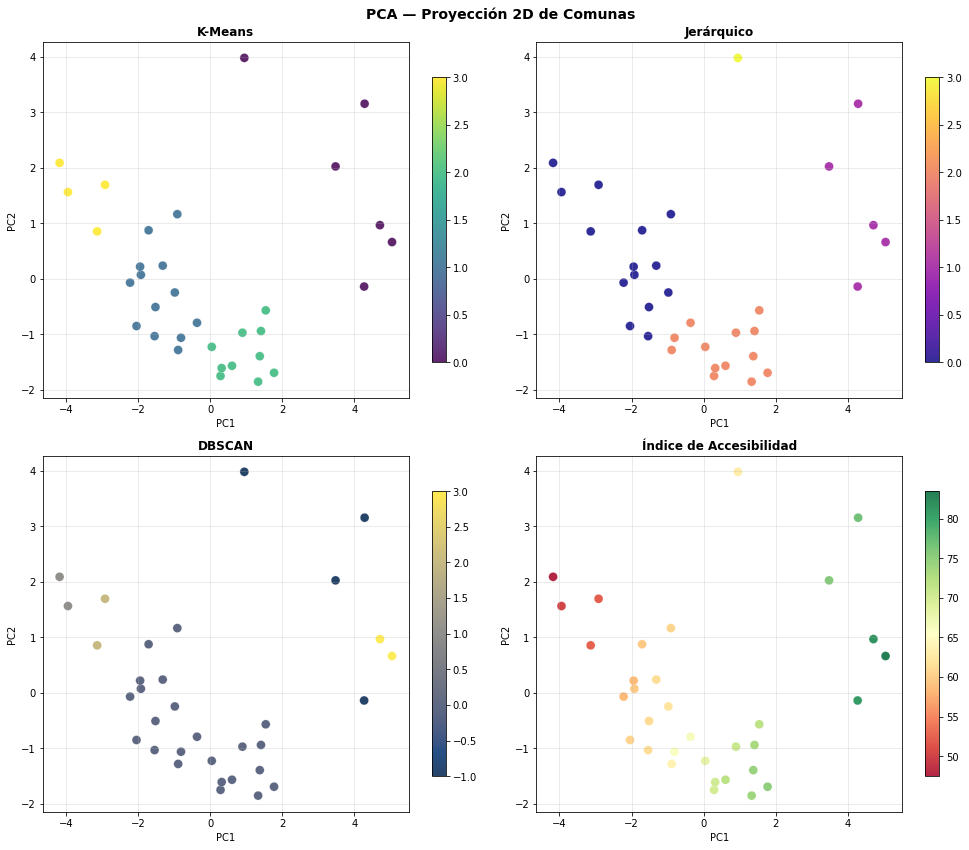

In [23]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
configs = [
    ('kmeans_cluster', 'K-Means',              'viridis'),
    ('agg_cluster',    'Jerárquico',            'plasma'),
    ('dbscan_cluster', 'DBSCAN',                'cividis'),
    ('indice_acceso',  'Índice de Accesibilidad','RdYlGn'),
]
for ax, (col, titulo, cmap) in zip(axes.flat, configs):
    sc = ax.scatter(pca_df['PC1'], pca_df['PC2'], c=pca_df[col],
                    cmap=cmap, s=80, alpha=0.85, edgecolors='white', linewidths=0.3)
    plt.colorbar(sc, ax=ax, shrink=0.8)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.grid(True, alpha=0.3)

plt.suptitle('PCA — Proyección 2D de Comunas', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

In [24]:
# Varianza explicada
var = pca.explained_variance_ratio_
print(f"Varianza explicada por PC1: {var[0]:.4f} ({var[0]*100:.1f}%)")
print(f"Varianza explicada por PC2: {var[1]:.4f} ({var[1]*100:.1f}%)")
print(f"Varianza acumulada (PC1+PC2): {sum(var):.4f} ({sum(var)*100:.1f}%)")

Varianza explicada por PC1: 0.7206 (72.1%)
Varianza explicada por PC2: 0.2631 (26.3%)
Varianza acumulada (PC1+PC2): 0.9838 (98.4%)


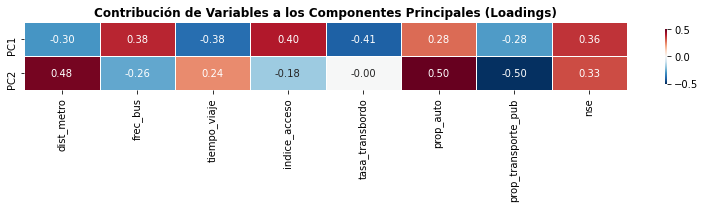


Loadings:
     dist_metro  frec_bus  tiempo_viaje  indice_acceso  tasa_transbordo  prop_auto  prop_transporte_pub    nse
PC1      -0.296     0.381        -0.383          0.401           -0.408      0.284               -0.284  0.363
PC2       0.479    -0.263         0.238         -0.181           -0.002      0.502               -0.502  0.328


In [25]:
# Heatmap de loadings
loadings_df = pd.DataFrame(pca.components_, columns=features, index=['PC1', 'PC2'])

fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(loadings_df, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            ax=ax, cbar_kws={'shrink': 0.8}, linewidths=0.5)
ax.set_title('Contribución de Variables a los Componentes Principales (Loadings)',
             fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

print("\nLoadings:")
print(loadings_df.round(3).to_string())

**📝 Interpretación PCA (Pauta):**

- **PC1 (72.1% varianza):** Contrasta accesibilidad vs. déficit. Carga positiva alta en `tasa_transbordo`, `tiempo_viaje`, `dist_metro`; carga negativa en `indice_acceso`, `frec_bus` y `nse`. Es el eje de **calidad del acceso al transporte**: valores bajos = buena conectividad, altos = periferia con déficit.
- **PC2 (26.3% varianza):** Contrasta el modo de transporte. Carga positiva en `dist_metro`, `prop_auto` y `nse`; negativa en `prop_transporte_pub`. Es el eje de **dependencia al automóvil**: valores altos = comunas de alto NSE lejos del metro que usan más auto (ej. Vitacura), valores bajos = comunas de bajo NSE con alta dependencia al TP.
- **Varianza acumulada: 98.4%** — Casi toda la información está en dos dimensiones, lo que indica alta estructura lineal en los datos.
- **Los clusters de K-Means son bien separables en el espacio PCA**, confirmando la idoneidad del algoritmo para este dataset.

### 5.2 Aplicación de UMAP

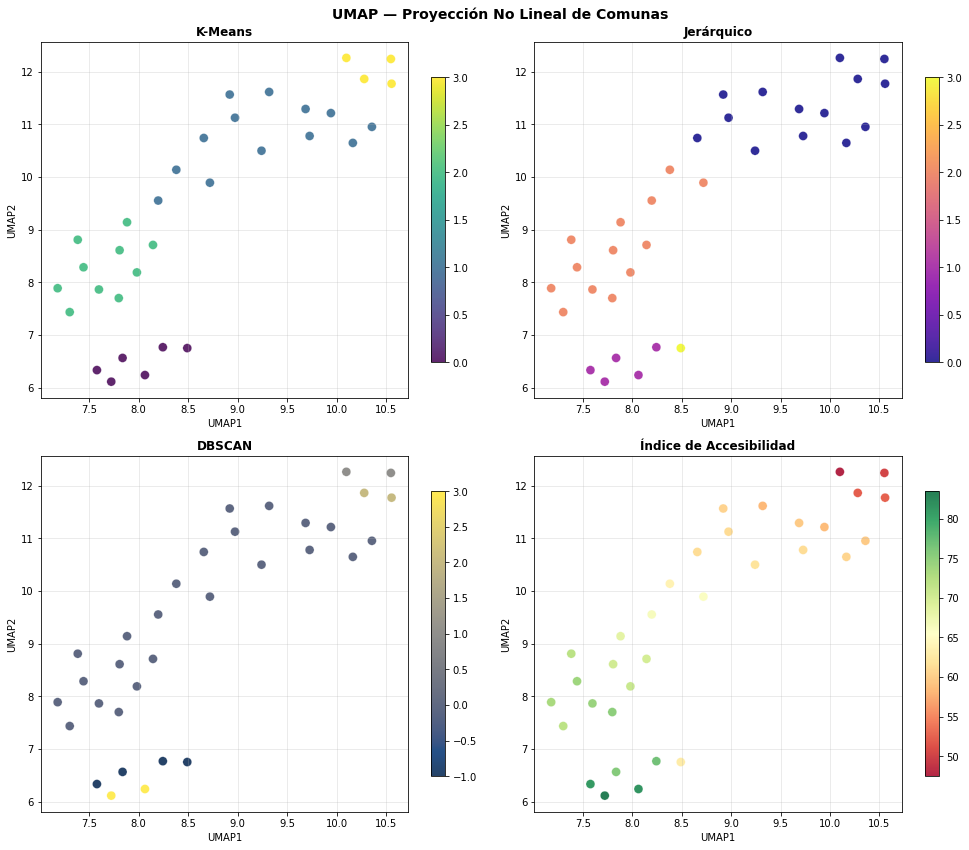

In [26]:
reducer = umap.UMAP(random_state=42)
embedding = reducer.fit_transform(X)

umap_df = pd.DataFrame({
    'comuna':         comuna_grouped['comuna'],
    'UMAP1':          embedding[:, 0],
    'UMAP2':          embedding[:, 1],
    'kmeans_cluster': comuna_scaled['kmeans_cluster'],
    'agg_cluster':    comuna_scaled['agg_cluster'],
    'dbscan_cluster': comuna_scaled['dbscan_cluster'],
    'gmm_cluster':    comuna_scaled['gmm_cluster'],
    'indice_acceso':  comuna_grouped['indice_acceso'],
})

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (col, titulo, cmap) in zip(axes.flat, configs):
    sc = ax.scatter(umap_df['UMAP1'], umap_df['UMAP2'], c=umap_df[col],
                    cmap=cmap, s=80, alpha=0.85, edgecolors='white', linewidths=0.3)
    plt.colorbar(sc, ax=ax, shrink=0.8)
    ax.set_title(titulo, fontsize=12, fontweight='bold')
    ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2')
    ax.grid(True, alpha=0.3)

plt.suptitle('UMAP — Proyección No Lineal de Comunas', fontsize=14, fontweight='bold')
plt.tight_layout(); plt.show()

**📝 Interpretación UMAP (Pauta):**

- UMAP tiende a separar más nítidamente los clusters que PCA en este dataset, formando "islas" más compactas.
- Los grupos identificados por K-Means mantienen coherencia espacial en ambas proyecciones, lo que refuerza la validez del clustering.
- A diferencia de PCA, UMAP no tiene una interpretación directa de los ejes; su valor es visual.
- Aceptar que el estudiante mencione que UMAP preserva mejor la estructura local y puede revelar sub-agrupaciones no visibles con PCA.

---
## Parte 6: Análisis Geoespacial — Mapa de Déficit de Accesibilidad

### 6.1 Mapa de Calor KDE Ponderado

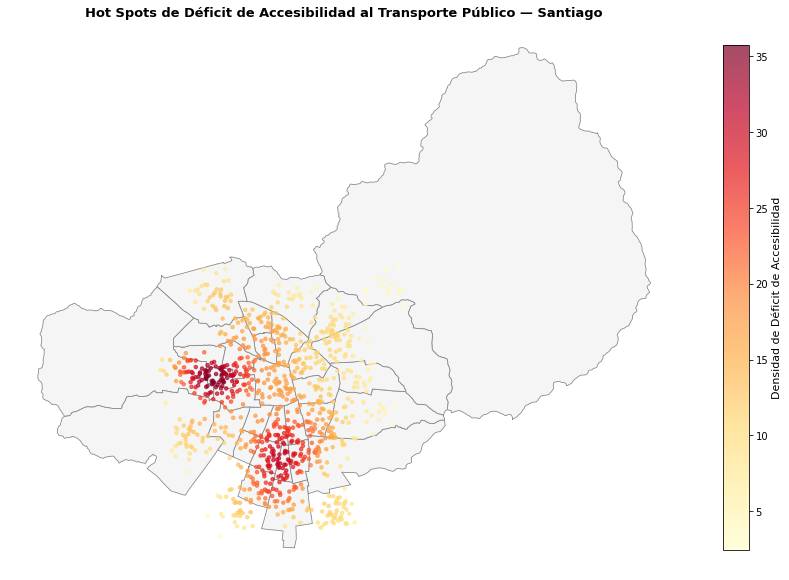

In [27]:
lon    = df_mov['longitud'].values
lat    = df_mov['latitud'].values
pesos  = (100 - df_mov['indice_acceso'].values)  # Déficit = 100 - acceso

kde = gaussian_kde(np.vstack([lon, lat]), weights=pesos)
densidades = kde(np.vstack([lon, lat]))
orden = densidades.argsort()

fig, ax = plt.subplots(1, 1, figsize=(12, 12))
df_stgo_merged.plot(ax=ax, color='#f5f5f5', edgecolor='#888888', linewidth=0.8)
sc = ax.scatter(lon[orden], lat[orden], c=densidades[orden],
                cmap='YlOrRd', s=12, alpha=0.7)
cbar = plt.colorbar(sc, ax=ax, shrink=0.6)
cbar.set_label('Densidad de Déficit de Accesibilidad', fontsize=11)
ax.set_title('Hot Spots de Déficit de Accesibilidad al Transporte Público — Santiago',
             fontsize=13, fontweight='bold')
ax.axis('off')
plt.tight_layout()
plt.show()

**📝 Interpretación KDE (Pauta):**

- Los hot spots de déficit se concentran en la **zona poniente** (Pudahuel, Cerro Navia, Maipú) y **periferia sur** (La Pintana, San Bernardo, Quilicura).
- Esta distribución es coherente con la realidad de Santiago: la red de metro cubre principalmente el eje central y oriente, dejando amplias zonas poniente y sur periféricas con menor frecuencia y mayor distancia a estaciones.
- El mapa permite identificar candidatos prioritarios para políticas de extensión de red o de mejora de alimentadores de transporte.

---
## Parte 7: Preguntas de Análisis — Respuestas Esperadas (Pauta)

### 7.1 Análisis Sociourbano y de Movilidad

---

**1. ¿Es posible identificar patrones de segregación en el acceso al transporte público?**

Sí, el análisis revela una segregación espacial clara en el acceso al transporte público de Santiago. Las comunas del sector oriente (Las Condes, Providencia, Ñuñoa, Vitacura) presentan los índices de accesibilidad más altos (>75), mientras que las comunas periféricas de la zona poniente y sur (Pudahuel, Cerro Navia, La Pintana, Quilicura) registran los valores más bajos (<55). Esta diferencia es estadísticamente significativa: el cluster de periferia extrema (cluster 3) tiene un índice promedio de 50.6, frente a 76.9 del cluster de alta accesibilidad (cluster 0), una brecha de más de 26 puntos.

El patrón espacial sigue un gradiente centro-periferia, donde la accesibilidad disminuye a medida que aumenta la distancia al centro histórico y a las líneas de metro.

---

**2. ¿Existe correlación entre NSE e índice de accesibilidad?**

La correlación entre `nse` e `indice_acceso` es positiva y moderada-alta (+0.63 en la matriz de correlación). Sin embargo, la relación no es estrictamente lineal: comunas como Santiago Centro tienen NSE medio pero alta accesibilidad (por su cercanía al metro), mientras que Vitacura tiene NSE muy alto pero accesibilidad moderada por su dependencia al automóvil privado.

Esto revela que la accesibilidad al transporte público no es equivalente al NSE: es una variable con dinámica propia, influida por la densidad de red, la distancia al metro y la oferta de buses.

---

**3. Macrozonas de movilidad:**

| Macrozona | Comunas representativas | Características |
|---|---|---|
| **Conectada central** | Providencia, Ñuñoa, Santiago, Macul, Estación Central | Cercanas al metro, alta frecuencia bus, tiempo viaje corto |
| **Oriente dependiente del auto** | Las Condes, Vitacura, Lo Barnechea, La Reina | Alto NSE, alta prop. auto, acceso moderado al metro |
| **Periférica con déficit** | Pudahuel, Cerro Navia, Quilicura, La Pintana, Maipú | Lejos del metro, alta tasa transbordo, mayor tiempo viaje |

---

**4. Propuestas de política pública:**

- **Extensión de líneas de metro hacia el poniente:** El análisis muestra que las zonas de mayor déficit (Pudahuel, Cerro Navia) tienen distancias al metro de 4–5 km. Una extensión de la Línea 1 o creación de una nueva línea reduciría el índice de transbordo y tiempo de viaje.
- **Corredores de buses de alta frecuencia en periferia:** El cluster 3 tiene frecuencias de bus de apenas 10–14 buses/hora. Aumentar la frecuencia y crear troncales exprés en los ejes poniente reduciría el tiempo de espera sin requerir infraestructura de metro.

**Nota docente:** Se aceptan otras propuestas fundamentadas. El criterio es que estén respaldadas en evidencia cuantitativa del análisis (citar métricas específicas).

### 7.2 Comparación de Algoritmos

---

**1. Diferencias fundamentales y evidencia cuantitativa:**

| Algoritmo | Silueta | Ventaja | Limitación |
|---|---|---|---|
| **K-Means** | 0.4785 | Clusters balanceados e interpretables | Asume clusters esféricos; sensible a outliers |
| **Jerárquico (complete)** | 0.4799 | Mejor silueta; dendrograma útil para exploración | No escala bien; difícil ajustar número de grupos |
| **DBSCAN** | 0.3290 | Detecta outliers (4 comunas atípicas) | Silueta más baja; sensible a parámetros eps/min_samples |
| **GMM** | 0.4637 | Modela distribuciones elípticas; probabilístico | Mayor complejidad; puede sobreajustar en datasets pequeños |

El **Clustering Jerárquico con enlace completo** obtiene la silueta más alta (0.4799) y produce grupos coherentes con la geografía de Santiago. K-Means es muy cercano (0.4785) y más fácil de interpretar.

---

**2. Algoritmo más adecuado para datos geoespaciales con componente socioeconómica:**

**K-Means** o **Clustering Jerárquico** son más adecuados por:
- Producen particiones completas (sin puntos de ruido), útil cuando todas las comunas deben quedar asignadas a un perfil.
- Sus parámetros (k) son más intuitivos que eps/min_samples de DBSCAN.
- En datasets pequeños como este (33 comunas), GMM puede sobreajustar.

DBSCAN es valioso como **diagnóstico complementario**: los 4 puntos que clasifica como ruido corresponden a comunas con perfiles mixtos (ej. Santiago Centro, que tiene NSE moderado pero alta accesibilidad por su ubicación central).

---

**3. Interpretación del dendrograma:**

Los sub-clusters más cohesivos corresponden a:
- **{Providencia, Ñuñoa}** — perfiles similares en todas las variables.
- **{Pudahuel, Cerro Navia, Quilicura}** — periferia poniente/norte con alto déficit.
- **{La Pintana, San Bernardo}** — periferia sur con características similares.

Esta agrupación tiene sentido geográfico: comunas contiguas suelen compartir infraestructura de transporte.

---

**4. Limitaciones metodológicas:**

- **Escala de agregación:** Los datos se agregan a nivel comunal, perdiendo variabilidad intra-comunal. Comunas grandes como Maipú tienen sectores muy heterogéneos que este análisis homogeneiza.
- **Variables proxy:** El `indice_acceso` es sintético; en datos reales conviene usar datos de la Encuesta Origen-Destino, registros Bip! u otros administrativos.
- **Estacionalidad y temporalidad:** Los datos representan un instante; la movilidad varía por hora, día y temporada.
- **Variables omitidas:** No se incluye densidad de ciclovías, distancia a paraderos, confiabilidad del servicio ni tarifa efectiva.

**Nota docente:** Se esperan al menos 2 limitaciones bien argumentadas. Otorgar puntaje adicional si proponen soluciones metodológicas concretas.

### 7.3 PCA vs. UMAP

---

**1. Varianza y contribución de variables:**

PC1 y PC2 explican en conjunto el **98.4% de la varianza total**, lo que es excepcionalmente alto. Esto indica que las variables de movilidad tienen una estructura muy correlacionada y casi toda la información relevante puede comprimirse en dos dimensiones.

- **PC1** contrasta accesibilidad vs. déficit: variables de alta carga positiva (`tasa_transbordo`, `tiempo_viaje`, `dist_metro`) vs. negativa (`indice_acceso`, `frec_bus`, `nse`). Es el **eje de calidad del acceso**.
- **PC2** contrasta dependencia al auto vs. transporte público: `prop_auto` y `nse` positivos vs. `prop_transporte_pub` negativo. Es el **eje de modo de transporte**.

---

**2. Comparación PCA vs. UMAP:**

Ambas proyecciones revelan estructuras similares. Sin embargo:
- **PCA** produce una proyección lineal con ejes interpretables; los clusters son visibles pero con algo de solapamiento entre clusters intermedios.
- **UMAP** tiende a separar más nítidamente los grupos, formando "islas" más compactas. Esto se debe a que UMAP preserva mejor la estructura local (comunas vecinas en el espacio de variables quedan más cercanas en la proyección).
- Los clusters K-Means son claramente separables en ambas proyecciones, lo que confirma que el clustering captura estructura real en los datos.
- **La alta varianza acumulada de PCA (98.4%) sugiere que en este caso PCA es suficiente** para visualización. UMAP sería más ventajoso con datos de mayor dimensionalidad o estructura no lineal más compleja.

**Nota docente:** El estudiante debe mencionar al menos: % varianza PC1+PC2, interpretación de al menos un eje, y una diferencia concreta entre PCA y UMAP.